# Visibility-aware hybrid embedding

This is the pipeline I used for the E23 → E23 analysis on a selected MICrONS V1 population. The idea is to learn one embedding per neuron, combine it with position, and predict whether a directed connection was observed. I also added a visibility branch to account for connections that may have been missed during reconstruction.

## What the model does

The connection branch uses each neuron's position and learned embedding. The visibility branch uses the distance between the two neurons and the presynaptic axon's proofreading category. For a fully extended axon, I set $p_{error}$ to zero. The model is trained on observed binary edges with unweighted binary cross entropy:

$$p_{obs}=p_{conn}(1-p_{error})$$

I initially tried using dendrite reconstruction too. In these data, high axon and dendrite reconstruction levels usually go together; the few mixed cases behaved oddly when I constrained $p_{error}$ too much. So I kept the presynaptic axon category only in this version. Dendrite metadata are still loaded, but they do not enter the error branch.

## Running it

The main pipeline is sections 1–22. The later sections are extra analyses; some need the optional readout files listed below. Required packages are `numpy`, `pandas`, `matplotlib`, `torch`, `scikit-learn`, `scipy` and `h5py`, plus Jupyter for `display`. I did not record the exact package versions from the original run.

| Input | Used for |
| --- | --- |
| `units_L234.csv` | Neuron IDs, positions, layer/class, proofreading and functional metadata |
| `synapses_L234.csv` | Observed directed synaptic pairs; multiple synapses collapse to a binary edge |
| `MICrONS\readout_info\foundation_model.pkl` | Optional functional readout vectors; load only a trusted pickle (I can't host MICrONS's Functional Activity Dataset & Reader a.k.a MICrONS in my code due to its size but you can easily dowload it here : https://huggingface.co/datasets/NeuroBLab/MICrONS) |
| `MICrONS\microns.h5` | Optional readout unit identifiers and metadata |
| `coreg_v1300.csv` | Optional functional/structural correspondence |
| `CHECKPOINT_DIR/best_dim_*.pt` and `last_dim_*.pt` | Learned states and training resumption; load only trusted checkpoints |
| `baselines/geometry_mlp_probability_vs_distance.csv` | Legacy optional comparison; its curve is currently disabled |

Paths are relative to the working directory. The readout paths use Windows separators, so they need adapting elsewhere. Data and checkpoints are not embedded here. The checkpoint folder name is historical; the active settings are in the configuration cell and model constructor (100 epochs, patience 10, connection hidden size 64, error hidden size 32).

The selected population is `pathways[0]` (currently E23 → E23). Use a separate checkpoint folder for each population/configuration. If you reuse a checkpoint, keep the same input data and ordered neuron IDs: the checkpoint does not store the ID order, split indices or a data fingerprint.

## A few things to keep in mind

- A negative label means “not observed”, not “biologically absent”. The fully extended axon constraint is an assumption. A good observed-label AUC does not by itself validate the visibility estimates or separate $p_{conn}$ from $p_{visible}$.
- The 80/10/10 split is by directed pair, not by neuron. The same neurons, and possibly reverse pairs, can appear in different splits, so this is a transductive evaluation. Position and distance scaling use all candidate pairs before the split.
- I report AUC on observed labels. I did not add multi-seed uncertainty, PR-AUC or calibration. The extra plots are exploratory and use all candidate pairs; the correlation scans do not correct for multiple comparisons.
- The readout-to-embedding analysis has a held-out-neuron split, but the embeddings were learned transductively first. It does not test connectivity prediction on unseen neurons.
- Building every pre × post pair takes quadratic memory, and all pair tensors are moved to the selected device before the split.

## One note on the saved notebook

I cleared the old outputs because some were from an earlier version of the code and one showed a checkpoint-loading error. I haven't rerun the notebook as part of cleaning it up, so there are no fresh results shown here. To reproduce the run, use the listed inputs and matching checkpoints.

## 1. Core imports

Numerical arrays, tabular metadata and plotting. Later sections import their additional dependencies locally.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load neuron metadata

Inspect the stored proofreading labels before any filtering. The string `none` is a category; it is distinct from a missing value.


In [2]:
units = pd.read_csv('units_L234.csv').copy()

print(units["strategy_axon"].value_counts(dropna=False))
print(units["strategy_dendrite"].value_counts(dropna=False))

strategy_axon
none                       23799
axon_partially_extended      916
axon_fully_extended           43
axon_interareal               13
Name: count, dtype: int64
strategy_dendrite
none                 23795
dendrite_extended      498
dendrite_clean         478
Name: count, dtype: int64


## 3. Anatomical filtering

Keep V1 neurons from layers L2/3 and L4. Root IDs use int64 to preserve large identifiers; positions are converted to float32. All listed columns must exist.


In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

## 4. Spatial region of interest

Select the open rectangle 500 < x < 800 and 700 < z < 1000 in the coordinates supplied by the CSV. Proofread neurons are plotted for context, but are not the only neurons retained.


selected_mask (6397, 11)


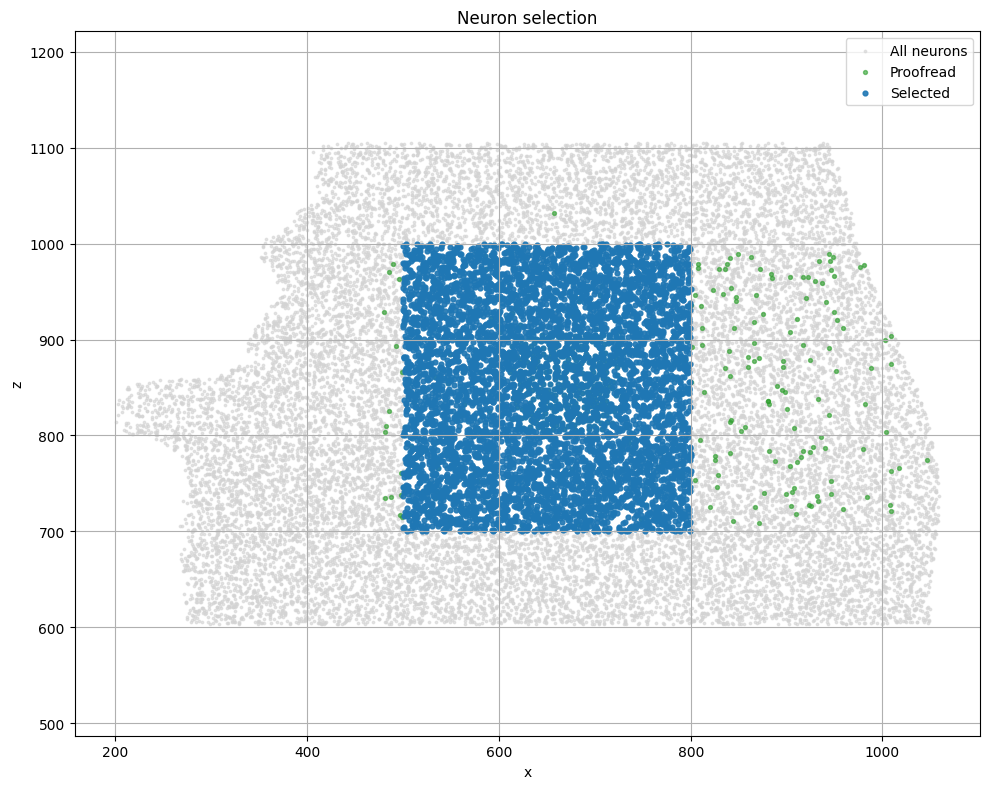

In [4]:
units_cleaned = clean_dataset(units)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

selected_mask = units_cleaned[(units_cleaned["pt_position_z"] < 1000) & (units_cleaned["pt_position_z"] > 700) & (units_cleaned["pt_position_x"] > 500) & (units_cleaned["pt_position_x"] < 800)]

print("selected_mask", selected_mask.shape)

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    selected_mask["pt_position_x"],
    selected_mask["pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

## 5. Population masks

Separate excitatory/inhibitory classes and layers. Unrecognised classifications are excluded from the named populations.


In [5]:
mask_exc = (selected_mask['classification_system'] == 'excitatory_neuron')
mask_inh = (selected_mask['classification_system'] == 'inhibitory_neuron')

mask_l23 = (selected_mask['layer'] == 'L2/3')
mask_l4 = (selected_mask['layer'] == 'L4')

## 6. Population tables

Reset DataFrame row indices for convenience; biological identity remains `pt_root_id`.


In [6]:
E_L23 = selected_mask[mask_exc & mask_l23].copy().reset_index(drop=True)
print(E_L23.shape)
I_L23 = selected_mask[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = selected_mask[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = selected_mask[mask_inh & mask_l4].copy().reset_index(drop=True)

print(E_L23)

(3398, 11)
              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135275621605     524.797852     223.267166     719.960022   
1     864691135738006641     501.233734     104.152145     960.080017   
2     864691135754570189     534.967834     225.249084     904.119995   
3     864691135763941174     613.394775     104.264053     927.880005   
4     864691136488446226     547.738770     131.413071     711.880005   
...                  ...            ...            ...            ...   
3393  864691136238038799     708.155273     187.977524     799.599976   
3394  864691135778700477     661.907227     120.329323     830.760010   
3395  864691135492080871     650.922607     107.097603     847.359985   
3396  864691135865698780     766.132935     117.883888     999.400024   
3397  864691136195316456     640.180115      76.412567     998.919983   

     classification_system  strategy_dendrite            strategy_axon layer  \
0        excitatory_neuron  dend

## 7. Directed pathways and synapses

The list defines directed pre → post populations. Only the pathway selected later is trained. Synapse sizes are mean-normalized here, but training uses binary existence labels rather than sizes or counts.


In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

## 8. Circular orientation difference

Orientation is periodic modulo π. The result is a signed wrapped difference in [−π/2, π/2), assuming radians.


In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

## 9. Polar orientation distance

Double-angle embedding respects orientation equivalence modulo π. This helper is not used by the current Euclidean-only training configuration.


In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

## 10. Observed connection rows

Filter observed synapses to the chosen populations, merge positions and remove self-connections. This can still contain multiple synapses per directed neuron pair; `build_dataset` later deduplicates them. The optional orientation filter compares against the literal string `True`, so check CSV dtypes before activating it.


In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

## 11. Proofreading category encodings

These fixed orders determine one-hot input semantics and must remain unchanged when reusing a checkpoint. Unknown labels are mapped to `none` downstream.


In [11]:
AXON_CATEGORIES = [
    "none",
    "axon_partially_extended",
    "axon_fully_extended",
    "axon_interareal",
]

DENDRITE_CATEGORIES = [
    "none",
    "dendrite_extended",
    "dendrite_clean",
]

AXON_TO_INDEX = {
    name: index
    for index, name in enumerate(AXON_CATEGORIES)
}

DENDRITE_TO_INDEX = {
    name: index
    for index, name in enumerate(DENDRITE_CATEGORIES)
}

## 12. Candidate directed pairs

Construct the full pre × post Cartesian product and remove self-pairs. Initially all candidates have label zero; observed positives take precedence during the merge. The full candidate table can be much larger than the synapse table.


In [12]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


## 13. Build the learning dataset

Return aligned pair indices, binary observed labels, raw and standardized geometry, and neuron-level proofreading metadata. The function also writes global `all_ids` and `id_map`; analyses rely on their order. Deduplication keeps the first observed synapse and does not aggregate synaptic weight. Standardized positions must not be used as physical Euclidean coordinates.


In [13]:
def build_dataset(
    pre_pop,
    post_pop,
    synapses,
    metric=["Euclidean"]
):
    """
    Build the potential neuron pairs and their connection labels.

    Returns:
    - raw pair features
    - connection labels
    - neuron indices
    - raw neuron positions in µm
    - global distance normalization parameters
    - normalized neuron positions
    - proofreading features
    """

    # ========================================================
    # Existing and potential connections
    # ========================================================

    conn_dist = existing_connections_v1(
        pre_pop,
        post_pop,
        synapses,
        metric
    ).copy()

    pot_dist = potential_connections_v1(
        pre_pop,
        post_pop,
        metric
    ).copy()

    print(
        "Existing connections:",
        len(conn_dist)
    )

    print(
        "Potential pairs:",
        len(pot_dist)
    )

    conn_dist["label"] = 1
    pot_dist["label"] = 0

    # Existing connections are placed first so that
    # they are kept when duplicates are removed.

    df = pd.concat(
        [
            conn_dist,
            pot_dist,
        ],
        ignore_index=True
    )

    df = (
        df
        .drop_duplicates(
            subset=[
                "pre_pt_root_id",
                "post_pt_root_id",
            ],
            keep="first"
        )
        .reset_index(drop=True)
    )

    print(
        "Number of unique pairs:",
        len(df)
    )

    # ========================================================
    # Neuron ID mapping
    # ========================================================

    global id_map, all_ids

    all_ids = pd.Index(
        pd.concat(
            [
                df["pre_pt_root_id"],
                df["post_pt_root_id"],
            ]
        ).unique()
    )

    id_map = {
        neuron_id: index
        for index, neuron_id in enumerate(all_ids)
    }

    pre_idx = (
        df["pre_pt_root_id"]
        .map(id_map)
        .to_numpy(dtype=np.int64)
    )

    post_idx = (
        df["post_pt_root_id"]
        .map(id_map)
        .to_numpy(dtype=np.int64)
    )

    # ========================================================
    # Neuron positions
    # ========================================================

    id_to_pos = (
        units_cleaned
        .drop_duplicates("pt_root_id")
        .set_index("pt_root_id")
        [
            [
                "pt_position_x",
                "pt_position_y",
                "pt_position_z",
            ]
        ]
    )

    # Raw positions in µm.
    # These positions must be used to calculate distance.

    positions_um = (
        id_to_pos
        .loc[np.asarray(all_ids)]
        .to_numpy(dtype=np.float32)
    )

    # Axis-wise normalized positions.
    # These can be used as inputs of P(connection),
    # but must not be used to calculate physical distance.

    positions = (
        positions_um
        - positions_um.mean(
            axis=0,
            keepdims=True
        )
    ) / (
        positions_um.std(
            axis=0,
            keepdims=True
        )
        + 1e-8
    )

    # ========================================================
    # Global scalar distance normalization
    # ========================================================

    if "euclidean" not in df.columns:
        raise ValueError(
            "The Euclidean distance is required. "
            "Use metric=['Euclidean']."
        )

    distance_mean = np.float32(
        df["euclidean"].mean()
    )

    distance_std = np.float32(
        df["euclidean"].std(
            ddof=0
        )
        + 1e-8
    )

    print(
        f"Distance mean: {distance_mean:.2f} µm"
    )

    print(
        f"Distance std: {distance_std:.2f} µm"
    )

    # ========================================================
    # Proofreading information
    # Ordered exactly like all_ids
    # ========================================================

    neuron_metadata = (
        units_cleaned
        .drop_duplicates("pt_root_id")
        .set_index("pt_root_id")
        .reindex(np.asarray(all_ids))
    )

    axon_labels = (
        neuron_metadata["strategy_axon"]
        .fillna("none")
        .astype(str)
        .to_numpy()
    )

    dendrite_labels = (
        neuron_metadata["strategy_dendrite"]
        .fillna("none")
        .astype(str)
        .to_numpy()
    )

    axon_indices = np.array(
        [
            AXON_TO_INDEX.get(
                label,
                AXON_TO_INDEX["none"]
            )
            for label in axon_labels
        ],
        dtype=np.int64
    )

    dendrite_indices = np.array(
        [
            DENDRITE_TO_INDEX.get(
                label,
                DENDRITE_TO_INDEX["none"]
            )
            for label in dendrite_labels
        ],
        dtype=np.int64
    )

    axon_features = np.eye(
        len(AXON_CATEGORIES),
        dtype=np.float32
    )[axon_indices]

    dendrite_features = np.eye(
        len(DENDRITE_CATEGORIES),
        dtype=np.float32
    )[dendrite_indices]

    # ========================================================
    # Fully proofread definitions
    # ========================================================

    axon_fully_proofread = (
        axon_labels
        == "axon_fully_extended"
    )

    dendrite_fully_proofread = (
        dendrite_labels
        == "dendrite_clean"
    )

    # ========================================================
    # Pair features and labels
    # ========================================================

    features = [
        "pre_pt_position_x",
        "pre_pt_position_y",
        "pre_pt_position_z",
        "post_pt_position_x",
        "post_pt_position_y",
        "post_pt_position_z",
    ]

    X = df[features].to_numpy(
        dtype=np.float32
    )

    y = df["label"].to_numpy(
        dtype=np.float32
    )

    # ========================================================
    # Return
    # ========================================================

    return (
        X,
        y,
        features,
        pre_idx,
        post_idx,
        positions_um,
        distance_mean,
        distance_std,
        positions,
        axon_features,
        dendrite_features,
        axon_fully_proofread,
        dendrite_fully_proofread,
    )

## 14. Select the experiment

Currently select E23 → E23. This initial build is a diagnostic preview; the training-data cell repeats it and overwrites the global ID mapping. Keep the population unchanged between these calls.


In [14]:
path, pre, post = pathways[0]
print(pre)
( _,
    y,
    _,
    pre_idx,
    post_idx,
    positions_um,
    distance_mean,
    distance_std,
    positions,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
) = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135275621605     524.797852     223.267166     719.960022   
1     864691135738006641     501.233734     104.152145     960.080017   
2     864691135754570189     534.967834     225.249084     904.119995   
3     864691135763941174     613.394775     104.264053     927.880005   
4     864691136488446226     547.738770     131.413071     711.880005   
...                  ...            ...            ...            ...   
3393  864691136238038799     708.155273     187.977524     799.599976   
3394  864691135778700477     661.907227     120.329323     830.760010   
3395  864691135492080871     650.922607     107.097603     847.359985   
3396  864691135865698780     766.132935     117.883888     999.400024   
3397  864691136195316456     640.180115      76.412567     998.919983   

     classification_system  strategy_dendrite            strategy_axon layer  \
0        excitatory_neuron  dendrite_extend

## 15. Training configuration

Set the compute device, checkpoint directory, dimensions and split fractions. The directory name is historical and does not describe all active hyperparameters. A fixed seed improves repeatability but does not guarantee deterministic GPU execution.


In [15]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_hybridV3_gesture_proofread_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 100
PATIENCE = 10
LR = 1e-3
DIMS = [1,2,3]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 16. Hybrid connectivity and visibility model

The same learned embedding table is used for pre- and postsynaptic roles; the ordered concatenation lets the connection MLP model directionality. Geometry enters both branches differently. Despite retained dendrite buffers, the current visibility mechanism depends only on presynaptic axon category and physical distance. Registered buffers travel with the model state.


In [16]:
import torch
import torch.nn as nn


class VisibilityAwareEmbeddingModel(nn.Module):

    def __init__(
        self,
        n_neurons,
        dim,
        positions,
        positions_um,
        distance_mean,
        distance_std,
        axon_features,
        dendrite_features,
        axon_fully_proofread,
        dendrite_fully_proofread,
        hidden_connection=64,
        hidden_error=32,
    ):
        super().__init__()

        self.dim = dim

        # ====================================================
        # Latent embedding
        # ====================================================

        self.Z = nn.Embedding(
            n_neurons,
            dim
        )

        nn.init.normal_(
            self.Z.weight,
            mean=0.0,
            std=0.1
        )

        # ====================================================
        # Fixed neuron information
        # ====================================================

        # Axis-wise normalized positions for P(connection)

        self.register_buffer(
            "positions",
            torch.as_tensor(
                positions,
                dtype=torch.float32
            )
        )

        # True positions in µm for P(error)

        self.register_buffer(
            "positions_um",
            torch.as_tensor(
                positions_um,
                dtype=torch.float32
            )
        )

        # Scalar distance normalization

        self.register_buffer(
            "distance_mean",
            torch.as_tensor(
                distance_mean,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "distance_std",
            torch.as_tensor(
                distance_std,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "axon_features",
            torch.as_tensor(
                axon_features,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "dendrite_features",
            torch.as_tensor(
                dendrite_features,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "axon_fully_proofread",
            torch.as_tensor(
                axon_fully_proofread,
                dtype=torch.bool
            )
        )

        self.register_buffer(
            "dendrite_fully_proofread",
            torch.as_tensor(
                dendrite_fully_proofread,
                dtype=torch.bool
            )
        )

        # ====================================================
        # P(connection)
        #
        # Inputs:
        # - normalized pre position: 3
        # - pre latent variables: dim
        # - normalized post position: 3
        # - post latent variables: dim
        # ====================================================

        neuron_feature_dim = 3 + dim
        connection_input_dim = 2 * neuron_feature_dim

        self.connection_mlp = nn.Sequential(
            nn.Linear(
                connection_input_dim,
                hidden_connection
            ),
            nn.ReLU(),
            nn.Linear(
                hidden_connection,
                1
            )
        )

        # ====================================================
        # P(error)
        #
        # Inputs:
        # - normalized physical distance: 1
        # - pre axon category
        # Dendrite features are retained as buffers but are not used here.
        # ====================================================

        error_input_dim = (
            1
            + len(AXON_CATEGORIES)
        )

        self.error_mlp = nn.Sequential(
            nn.Linear(
                error_input_dim,
                hidden_error
            ),
            nn.ReLU(),
            nn.Linear(
                hidden_error,
                1
            )
        )

        # Initially predict a small error probability

        nn.init.constant_(
            self.error_mlp[-1].bias,
            -3.0
        )

    def forward_components(
        self,
        pre_idx,
        post_idx
    ):

        # ====================================================
        # Positions
        # ====================================================

        # Normalized positions for P(connection)

        pos_pre = self.positions[pre_idx]
        pos_post = self.positions[post_idx]

        # True positions in µm for P(error)

        pos_pre_um = self.positions_um[pre_idx]
        pos_post_um = self.positions_um[post_idx]

        # ====================================================
        # 1. True connection probability
        # ====================================================

        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        h_pre = torch.cat(
            [
                pos_pre,
                z_pre,
            ],
            dim=1
        )

        h_post = torch.cat(
            [
                pos_post,
                z_post,
            ],
            dim=1
        )

        connection_input = torch.cat(
            [
                h_pre,
                h_post,
            ],
            dim=1
        )

        connection_logits = (
            self.connection_mlp(
                connection_input
            )
            .squeeze(1)
        )

        p_connection = torch.sigmoid(
            connection_logits
        )

        # ====================================================
        # 2. Error probability
        # ====================================================

        axon_pre = self.axon_features[
            pre_idx
        ]

        dendrite_post = self.dendrite_features[
            post_idx
        ]

        # True physical distance in µm

        distance_um = torch.linalg.vector_norm(
            pos_pre_um - pos_post_um,
            dim=1
        )

        # Scalar centered and reduced distance

        distance = (
            distance_um
            - self.distance_mean
        ) / self.distance_std

        distance = distance.unsqueeze(1)

        error_input = torch.cat(
            [
                distance,
                axon_pre
            ],
            dim=1
        )

        error_logits = (
            self.error_mlp(
                error_input
            )
            .squeeze(1)
        )

        p_error_raw = torch.sigmoid(
            error_logits
        )

        # ====================================================
        # Hard constraint
        #
        # Fully extended presynaptic axon (dendrite is not used):
        # P(error) = 0
        # ====================================================

        fully_proofread_pair = (
            self.axon_fully_proofread[pre_idx]
        )

        p_error = torch.where(
            fully_proofread_pair,
            torch.zeros_like(
                p_error_raw
            ),
            p_error_raw
        )

        p_visible = 1.0 - p_error

        # ====================================================
        # Observed connection probability
        # ====================================================

        p_observed = (
            p_connection
            * p_visible
        )

        p_observed = torch.clamp(
            p_observed,
            min=1e-7,
            max=1.0 - 1e-7
        )

        return {
            "p_observed": p_observed,
            "p_connection": p_connection,
            "p_visible": p_visible,
            "p_error": p_error,
            "distance_um": distance_um,
            "distance_normalized": distance.squeeze(1),
            "fully_proofread_pair": fully_proofread_pair,
        }

    def forward(
        self,
        pre_idx,
        post_idx
    ):

        return self.forward_components(
            pre_idx,
            post_idx
        )["p_observed"]

## 17. Transductive train/validation/test split

Split directed pairs with a seeded generator (80/10/remaining ≈10%). This is not a disjoint-neuron split. The complete tensors are already on DEVICE. AUC requires both classes in each evaluated subset; the split is random, not stratified.


In [17]:
# =========================
# Data
# =========================

(
    _,
    y,
    _,
    pre_idx,
    post_idx,
    positions_um,
    distance_mean,
    distance_std,
    positions,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
) = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

Existing connections: 100040
Potential pairs: 11543006
Number of unique pairs: 11543006
Distance mean: 174.10 µm
Distance std: 70.22 µm
n_neurons: 3398
n_pairs: 11543006
positive rate: 0.008666720241308212


## 18. Evaluate observed-label predictions

Compute a pair-weighted mean BCE and one global ROC-AUC. No gradients are calculated. Returned AUC is for observed connectivity, not the unobserved true-connection component.


In [18]:
def evaluate(model, loader, criterion):
    """
    Evaluate the model on a validation or test dataset.

    Returns:
        - Mean loss over all neuron pairs
        - Global AUC over all predictions
    """

    # Switch the model to evaluation mode
    model.eval()

    total_loss = 0.0
    all_y = []
    all_predictions = []

    # Gradients are not needed during evaluation
    with torch.no_grad():

        # Evaluate the dataset batch by batch
        for pi, pj, yb in loader:

            # Predict the observed connection probability
            p_observed = model(pi, pj)

            # Calculate the loss for the current batch
            loss = criterion(
                p_observed,
                yb
            )

            # Multiply by the batch size to calculate
            # the mean loss over the complete dataset
            total_loss += (
                loss.item() * len(yb)
            )

            # Move labels and predictions back to the CPU
            # and store them for the global AUC
            all_y.append(
                yb.cpu().numpy()
            )

            all_predictions.append(
                p_observed.cpu().numpy()
            )

    # Reassemble all batches into two complete arrays
    all_y = np.concatenate(all_y)

    all_predictions = np.concatenate(
        all_predictions
    )

    # Calculate one global AUC over the complete dataset
    auc = roc_auc_score(
        all_y,
        all_predictions
    )

    # Return the mean loss per pair and the global AUC
    return (
        total_loss / len(loader.dataset),
        auc
    )

## 19. Save and restore training state

Store model buffers/weights, optimizer, epoch metrics and random states. The best loss stored is the loss at the best-AUC epoch, not the minimum loss across all epochs. Checkpoints do not include a separate neuron-ID table or split fingerprint. Loading arbitrary pickle-based checkpoints is unsafe.


In [19]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    """
    Save everything required to resume the training from the same state.

    This includes the model, the optimizer, the training progress,
    the best validation metrics and the random number generator states.
    """

    torch.save({
        # Current training state
        "dim": dim,
        "epoch": epoch,

        # Learned model parameters
        "model_state_dict": model.state_dict(),

        # Adam internal state, including momentum estimates
        "optimizer_state_dict": optimizer.state_dict(),

        # Best validation results obtained so far
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Number of epochs without AUC improvement
        "epochs_without_improvement": epochs_without_improvement,

        # Results already obtained for the other dimensions
        "results": results,

        # Save the random generator states to make
        # resumed training as reproducible as possible
        "rng_state": torch.get_rng_state(),

        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),

        "numpy_rng_state": np.random.get_state(),

    }, path)


def load_checkpoint(path, model, optimizer):
    """
    Load a checkpoint and restore the complete training state.

    The returned dictionary also contains the epoch, metrics,
    early-stopping state and previously saved results.
    """

    # weights_only=False is required because the checkpoint also
    # contains NumPy states and other Python objects.
    # Only load checkpoints coming from a trusted source.
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore the learned model parameters
    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    # Restore the Adam state so that optimization can continue
    # from the same momentum and variance estimates
    optimizer.load_state_dict(
        ckpt["optimizer_state_dict"]
    )

    # Restore the PyTorch CPU random generator
    rng_state = ckpt.get(
        "rng_state",
        None
    )

    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(
                rng_state.cpu()
            )
        except Exception as e:
            print(
                "Warning: CPU rng_state ignored:",
                e
            )
    else:
        print(
            "Warning: CPU rng_state ignored."
        )

    # Restore the random generator for every available GPU
    cuda_rng_state = ckpt.get(
        "cuda_rng_state",
        None
    )

    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(
                cuda_rng_state
            )
        except Exception as e:
            print(
                "Warning: CUDA rng_state ignored:",
                e
            )

    # Restore the NumPy random generator
    numpy_rng_state = ckpt.get(
        "numpy_rng_state",
        None
    )

    if numpy_rng_state is not None:
        try:
            np.random.set_state(
                numpy_rng_state
            )
        except Exception as e:
            print(
                "Warning: NumPy rng_state ignored:",
                e
            )

    # Return the remaining information needed by the training loop
    return ckpt

## 20. Initialize the default training log

Set the dimension used by the initial CSV-header cell below. The training loop later iterates over every configured dimension.


In [20]:
import os

dim = 1  # Default dimension for the initial training-log header.


## 21. Initialize a training log

Create a CSV header without overwriting an existing log. The per-dimension training loop repeats this initialization where needed.


In [21]:
import csv

# One training log file is created for each latent dimension
log_csv_path = os.path.join(
    CHECKPOINT_DIR,
    f"training_log_dim_{dim}.csv"
)

# Create the file and its header if it does not already exist
if not os.path.exists(log_csv_path):
    with open(
        log_csv_path,
        "w",
        newline=""
    ) as f:

        writer = csv.writer(f)

        # Metrics saved after each epoch
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

## 22. Fit each latent dimension

Train with plain BCELoss and Adam; select the checkpoint using validation ROC-AUC and evaluate the selected state on test pairs. Patience is based on strictly improving AUC. Test results are descriptive comparisons: choose model dimension using validation rather than maximizing test AUC. Automatic resumption depends on compatible input ordering and checkpoints.


In [22]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Create the CSV if it does not exist
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = VisibilityAwareEmbeddingModel(
    n_neurons=n_neurons,
    dim=dim,
    positions=positions,
    positions_um=positions_um,
    distance_mean=distance_mean,
    distance_std=distance_std,
    axon_features=axon_features,
    dendrite_features=dendrite_features,
    axon_fully_proofread=axon_fully_proofread,
    dendrite_fully_proofread=dendrite_fully_proofread,
    ).to(DEVICE)

    # Plain, unweighted BCE on observed probabilities.
    #pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCELoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            p_observed = model(pi, pj)
            loss = criterion(p_observed, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results,
                epochs_without_improvement=epochs_without_improvement,
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results,
            epochs_without_improvement=epochs_without_improvement,
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
Resuming dim=1 from checkpoints_embedding_MLP_hybridV3_gesture_proofread_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple\last_dim_1.pt
Resumed at epoch 100 | best_epoch=95 | best_val_auc=0.8937
dim=1 already completed. Skipping training.

Training dim = 2
Resuming dim=2 from checkpoints_embedding_MLP_hybridV3_gesture_proofread_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple\last_dim_2.pt
Resumed at epoch 100 | best_epoch=97 | best_val_auc=0.9001
dim=2 already completed. Skipping training.

Training dim = 3
Resuming dim=3 from checkpoints_embedding_MLP_hybridV3_gesture_proofread_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple\last_dim_3.pt
Resumed at epoch 100 | best_epoch=98 | best_val_auc=0.9038
dim=3 already completed. Skipping training.

Final results:
{'dim': 1, 'best_epoch': 95, 'best_val_loss': 0.03840259883617659, 'best_val_auc': 0.8936879742225498,

## 23. Optional functional readout alignment

This section requires the pickle, HDF5 and coregistration CSV. It matches functional units to root IDs, filters residual < 30 and score > 0, and retains the highest-score correspondence per root ID. Row alignment between readout arrays and HDF5 unit IDs is assumed; using the minimum length can conceal a mismatch and deserves source-data verification. The HDF5 handle remains open for subsequent inspection.


In [25]:
import pickle
import h5py
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================

FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"
MICRONS_H5_PATH = "MICrONS\\microns.h5"
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load files
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)
    """{"session_scan": {
            mu: [mu_x, mu_x] #area of the vision field where focus on the neuron
            feature_weigth: [[128 features] * 4] visual caracteristic of this area learnt by a the model
        }
    }"""

h5 = h5py.File(MICRONS_H5_PATH, "r") #for more information see the folder on hugging face https://huggingface.co/datasets/NeuroBLab/MICrONS

coreg = pd.read_csv(COREG_PATH) #merging table with coreg["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]

print(coreg)


# ============================================================
# Build readout table
# ============================================================

def build_readout_df(model_dict, h5, model_name="model"):
    rows = []
    for session_scan, data in model_dict.items():
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        session, scan_idx = map(int, session_scan.split("_"))
        meta = h5["sessions"][session_scan]["meta"]
        print(meta.keys())
        unit_ids = meta["unit_ids"][:]
        weights = data["feature_weights"]
        mu = data["mu"]

        n = min(len(unit_ids), weights.shape[0], mu.shape[0])

        if len(unit_ids) != weights.shape[0]:
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, weights={weights.shape[0]}, using n={n}"
            )

        for i in range(n):
            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),
                "readout_weight": weights[i].reshape(-1).astype(np.float32),
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })
    return pd.DataFrame(rows)


readout_df = build_readout_df(foundation, h5)


# ============================================================
# Clean coreg table
# ============================================================

coreg = coreg[
    ["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]
].copy()

coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(np.int64)
print(coreg["score"].describe())

print(coreg["residual"].describe())

# ============================================================
# Merge readouts with pt_root_id
# ============================================================

readout_with_root = readout_df.merge(
    coreg,
    on=["session", "scan_idx", "unit_id"],
    how="inner"
)

readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 30)
    & (readout_with_root["score"] > 0)
].copy()

idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)

print("readout_df:", readout_df.shape)
print("readout_with_root:", readout_with_root.shape)
print("readout_with_root:", readout_with_root.shape)
print("matched fraction:", len(readout_with_root) / len(readout_df))



       id_ref                       created_ref  valid_ref     volume  \
0      388868  2020-09-28 22:44:53.222573+00:00       True  292.63200   
1      357165  2020-09-28 22:44:28.479993+00:00       True  254.62144   
2      323782  2020-09-28 22:45:16.004514+00:00       True  354.07840   
3      452040  2020-09-28 22:45:19.539072+00:00       True  374.22530   
4      485026  2020-09-28 22:44:53.278972+00:00       True  292.83008   
...       ...                               ...        ...        ...   
83041  326990  2020-09-28 22:43:47.135816+00:00       True  317.94562   
83042  191219  2020-09-28 22:41:37.134630+00:00       True  347.67667   
83043  259262  2020-09-28 22:40:55.410396+00:00       True  334.41168   
83044  422837  2020-09-28 22:42:45.050377+00:00       True  304.70242   
83045  553999  2020-09-28 22:41:18.478532+00:00       True  368.10376   

         pt_supervoxel_id          pt_root_id     id  \
0       97536645708182218  864691135801936738      1   
1       947

## 24. Load a selected embedding

Load `best_dim_1.pt` by default, then attach root IDs and neuron metadata in the exact original order. The repeated private-module import is an earlier environment workaround, not a robust PyTorch compatibility fix. The archived output contains a loading error; later stored results may come from another interactive kernel state.


In [26]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1
ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = VisibilityAwareEmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions,
    positions_um=positions_um,
    distance_mean=distance_mean,
    distance_std=distance_std,
    axon_features=axon_features,
    dendrite_features=dendrite_features,
    axon_fully_proofread=axon_fully_proofread,
    dendrite_fully_proofread=dendrite_fully_proofread,
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

# ============================================================
# Remove duplicates
# ============================================================

units_unique = (
    units_cleaned
    .drop_duplicates(
        subset="pt_root_id",
        keep="first"
    )
    .copy()
)

print(
    "Duplicates in units_unique:",
    units_unique["pt_root_id"].duplicated().sum()
)


# ============================================================
# Build df_Z_full
# ============================================================

df_Z_full = df_Z.merge(
    units_unique,
    on="pt_root_id",
    how="left"
)
print(df_Z_full.head())

Loaded model for dim=1
Best epoch: 95
Best val loss: 0.0384
Z shape: (3398, 1)
Duplicates in units_unique: 0
         z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0 -0.273120           0  864691134885142778     596.029358     126.515236   
1  0.263765           1  864691134885735418     788.885071     105.290947   
2  0.453210           2  864691134886095610     616.010559     190.387756   
3  0.149283           3  864691134917923338     544.262146     179.228012   
4  0.415699           4  864691134918694410     629.363098     150.118271   

   pt_position_z classification_system strategy_dendrite strategy_axon layer  \
0     984.679993     excitatory_neuron              none          none  L2/3   
1     978.760010     excitatory_neuron              none          none  L2/3   
2     745.520020     excitatory_neuron              none          none  L2/3   
3     986.200012     excitatory_neuron              none          none  L2/3   
4     804.919983     excitat

## 25. Anatomical 3D display

Color neurons by the first coordinate of the selected embedding. This is a descriptive visualization and does not measure predictive performance.


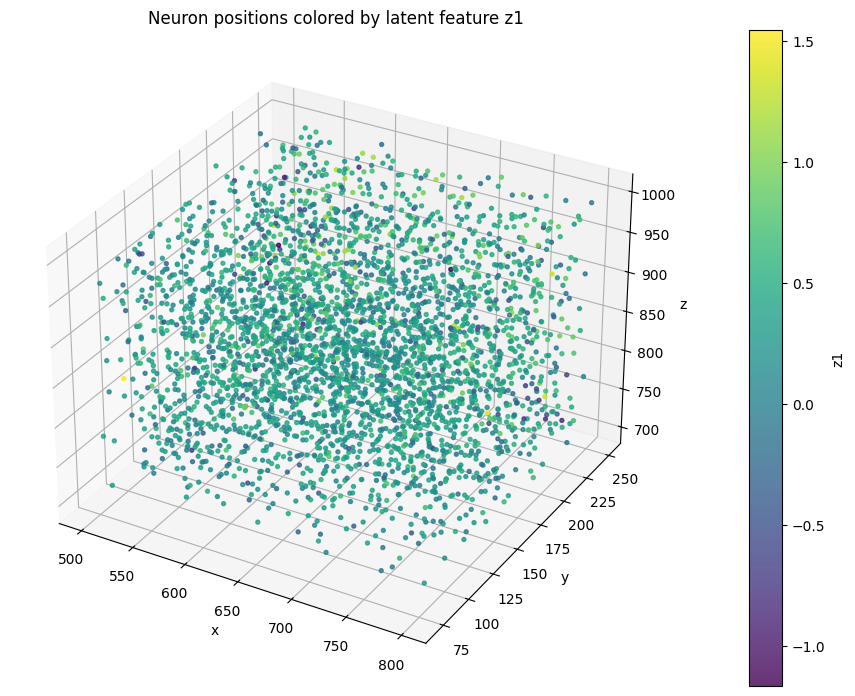

In [27]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

## 26. Anatomical projections

Show three projections with the same latent coordinate as color. These views help identify spatial organization of the embedding.


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


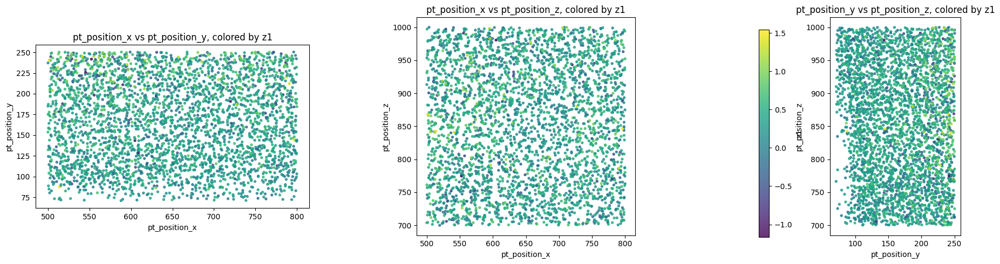

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

## 27. Readout-coordinate correlation scan

Merge optional readouts and scan Spearman correlations against 512 assumed readout coordinates. Verify the actual flattened readout width before running. The absolute-rho threshold is descriptive and is not a corrected significance criterion. Rerunning the merge cell without rebuilding `df_Z_full` can create suffixed duplicate columns.


In [29]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np


# ============================================================
# Data
# ============================================================

df_Z_full = df_Z_full.merge(readout_unique[ 
    ["pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

print(df_Z_full)


df_Z_readout = df_Z_full[
    df_Z_full["readout_weight"].notna()
].copy().reset_index(drop=True)
latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]

R = np.stack(df_Z_readout["readout_weight"].values)

print("R shape:", R.shape)

threshold = 0.30

results = []

# ============================================================
# Correlations
# ============================================================

for z in latent_cols:

    z_values = df_Z_readout[z].values

    for j in range(512):

        rho, pval = spearmanr(
            z_values,
            R[:, j]
        )

        if np.abs(rho) >= threshold:

            results.append({
                "latent": z,
                "readout_dim": j,
                "rho": rho,
                "abs_rho": abs(rho),
                "pvalue": pval,
            })

corr_df = pd.DataFrame(results)

"""corr_df = corr_df.sort_values(
    "abs_rho",
    ascending=False
)"""

print(corr_df)

            z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0    -0.273120           0  864691134885142778     596.029358     126.515236   
1     0.263765           1  864691134885735418     788.885071     105.290947   
2     0.453210           2  864691134886095610     616.010559     190.387756   
3     0.149283           3  864691134917923338     544.262146     179.228012   
4     0.415699           4  864691134918694410     629.363098     150.118271   
...        ...         ...                 ...            ...            ...   
3393  0.613748        3393  864691135911082153     759.395264      99.434456   
3394  0.829821        3394  864691135741004651     505.842499     243.130692   
3395  0.877228        3395  864691135429769520     766.894714     250.165649   
3396  0.539796        3396  864691136057171416     783.436584     128.648972   
3397  0.805000        3397  864691136371310728     756.323120     247.634644   

      pt_position_z classification_syst

## 28. Observed edge frequency in latent bins

Each bin shows the fraction of labelled observed edges among candidate pairs, pooling train, validation and test. It is not the inferred biological `p_connection` component and is not a held-out evaluation. Cells with fewer than 100 pairs are masked.


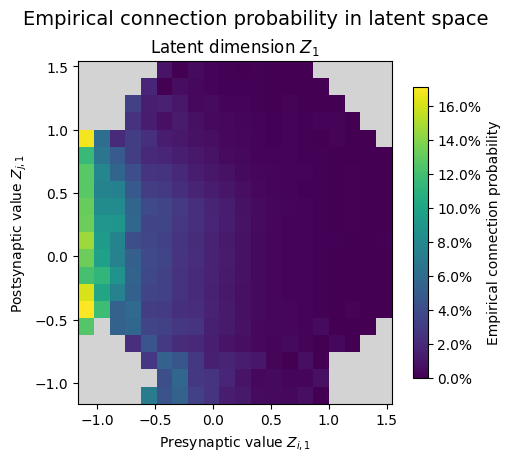

In [30]:
# ============================================================
# Empirical P(connection) as a function of Z_pre and Z_post
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


N_BINS = 20
MIN_PAIRS_PER_CELL = 100


# Existing tensors -> NumPy
pre_np = pre_idx.detach().cpu().numpy()
post_np = post_idx.detach().cpu().numpy()
y_np = y.detach().cpu().numpy()


heatmaps = []
edges_by_dim = []


# ============================================================
# Compute empirical probabilities
# ============================================================

for k in range(DIM_TO_ANALYZE):

    z_pre = Z[pre_np, k]
    z_post = Z[post_np, k]

    z_edges = np.linspace(
        min(z_pre.min(), z_post.min()),
        max(z_pre.max(), z_post.max()),
        N_BINS + 1,
    )

    # Number of possible connections in each cell
    n_possible, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
    )

    # Number of observed connections in each cell
    n_connections, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
        weights=y_np,
    )

    # P(connection) = observed / possible
    empirical_probability = np.divide(
        n_connections,
        n_possible,
        out=np.full_like(
            n_connections,
            np.nan,
            dtype=float,
        ),
        where=n_possible > 0,
    )

    empirical_probability[
        n_possible < MIN_PAIRS_PER_CELL
    ] = np.nan

    heatmaps.append(empirical_probability)
    edges_by_dim.append(z_edges)


# Common color scale
vmax = np.nanmax([
    np.nanmax(heatmap)
    for heatmap in heatmaps
])


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    DIM_TO_ANALYZE,
    figsize=(5 * DIM_TO_ANALYZE, 4.5),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgrey")


for k, ax in enumerate(axes):

    z_edges = edges_by_dim[k]

    im = ax.pcolormesh(
        z_edges,
        z_edges,
        heatmaps[k].T,
        shading="auto",
        cmap=cmap,
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(
        rf"Latent dimension $Z_{k+1}$"
    )

    ax.set_xlabel(
        rf"Presynaptic value $Z_{{i,{k+1}}}$"
    )

    ax.set_ylabel(
        rf"Postsynaptic value $Z_{{j,{k+1}}}$"
    )


colorbar = fig.colorbar(
    im,
    ax=axes.tolist(),
    shrink=0.85,
)

colorbar.set_label(
    "Empirical connection probability"
)

colorbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

fig.suptitle(
    "Empirical connection probability in latent space",
    fontsize=14,
)

plt.savefig(
    "empirical_connection_probability_latent_heatmaps.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 29. Choose metadata for correlation analysis

Select available biological columns and current latent coordinates. Optional readout variables are present only after their merge.


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
    "readout_mu_x",
    "readout_mu_y"
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit', 'readout_mu_x', 'readout_mu_y']


## 30. Metadata correlations

Pairwise complete-case Pearson and Spearman estimates; fewer than five valid rows produce NaN. P-values are uncorrected. Linear/rank correlation of raw circular angles may miss or distort orientation relationships.


In [32]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1      -0.031984       0.122048       0.022739      0.046496     -0.048217   

    readout_mu_y  
z1     -0.020416  

=== Pearson correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1      -0.023624       0.098521       0.021923      0.036693      -0.05499   

    readout_mu_y  
z1     -0.007136  


## 31. Correlation overview

Plot the previously calculated exploratory Spearman coefficients. The heatmap contains no independent validation or causal interpretation.


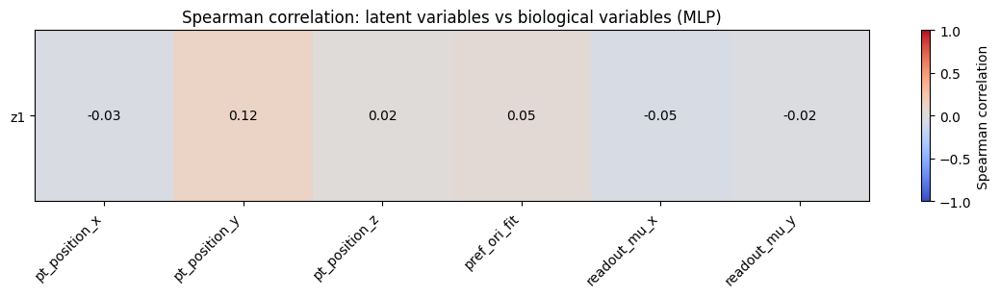

In [33]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

## 32. Strongest correlation examples

Show the six largest absolute correlations selected from the same data. Their selection makes them exploratory examples rather than independently confirmed findings.


=== Strongest correlations ===
z1  pt_position_y    0.122048
    readout_mu_x     0.048217
    pref_ori_fit     0.046496
    pt_position_x    0.031984
    pt_position_z    0.022739
    readout_mu_y     0.020416
dtype: float64


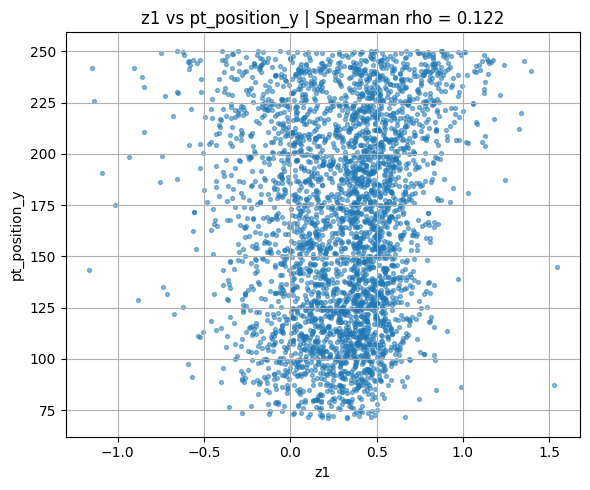

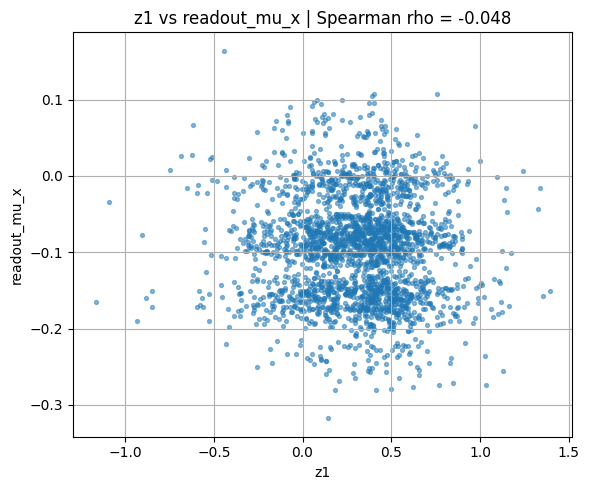

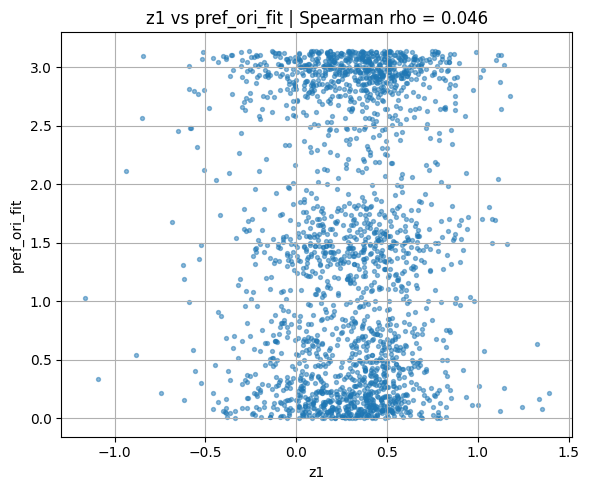

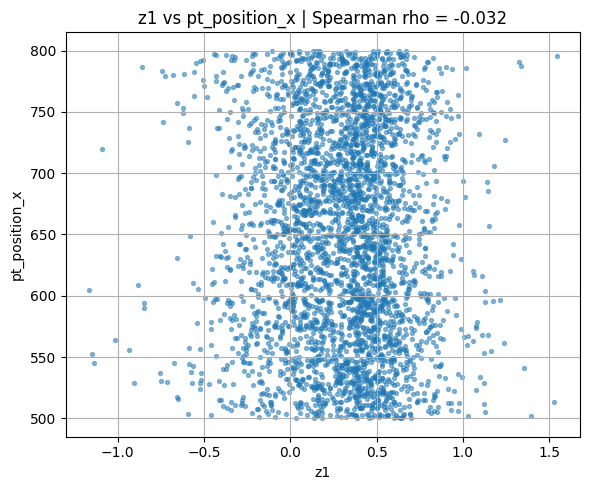

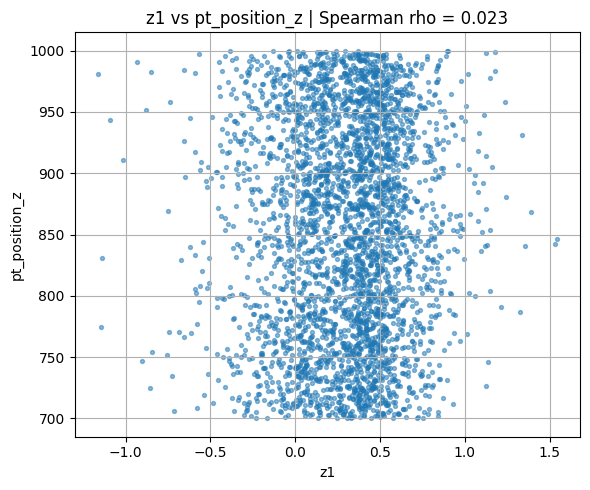

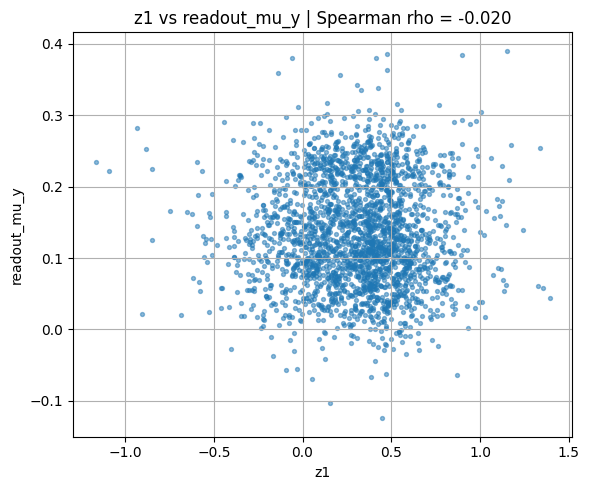

In [34]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

## 33. Optional PCA visualization

PCA provides a descriptive 2D projection when at least two latent coordinates were loaded. It is skipped for the default one-dimensional model.


In [35]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

PCA skipped: latent dimension < 2


## 34. Model visibility curves

Evaluate the error branch across the central 98% of test-pair physical distances, varying axon category. The fully extended category is fixed to visibility one by the hard constraint. Other curves are model-implied factors, not measured detection probabilities, and may extrapolate for sparsely represented category-distance combinations.


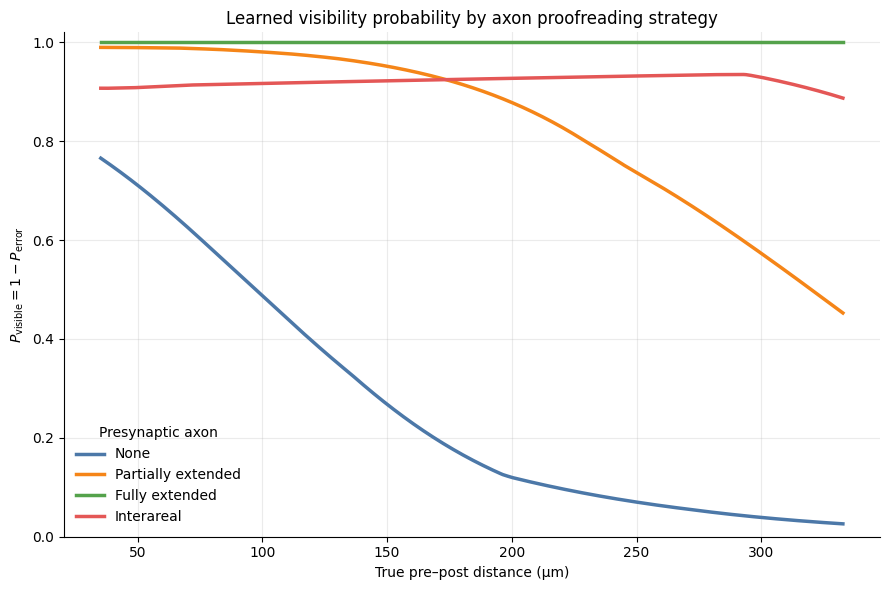

In [36]:
# ============================================================
# Learned P(visible) = 1 - P(error)
# for each axon proofreading strategy
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch


model.eval()

expected_error_input = (
    1
    + len(AXON_CATEGORIES)
)

assert model.error_mlp[0].in_features == expected_error_input, (
    f"error_mlp expects {model.error_mlp[0].in_features} inputs, "
    f"but {expected_error_input} are required."
)


# ============================================================
# True distance range observed in the test set
# ============================================================

test_indices = torch.as_tensor(
    np.asarray(test_set.indices),
    dtype=torch.long,
    device=DEVICE,
)

pre_test = pre_idx[test_indices]
post_test = post_idx[test_indices]


with torch.no_grad():

    observed_distances_um = torch.linalg.vector_norm(
        model.positions_um[pre_test]
        - model.positions_um[post_test],
        dim=1,
    )

    # Remove extreme outliers for a clearer graph

    min_distance_um = torch.quantile(
        observed_distances_um,
        0.01,
    ).item()

    max_distance_um = torch.quantile(
        observed_distances_um,
        0.99,
    ).item()


# Grid displayed in real µm

distance_grid_um = torch.linspace(
    min_distance_um,
    max_distance_um,
    300,
    device=DEVICE,
)

# Same distances normalized exactly as during training

distance_grid_normalized = (
    distance_grid_um
    - model.distance_mean
) / model.distance_std


# ============================================================
# Evaluate each axon proofreading strategy
# ============================================================

visibility_curves = {}


with torch.no_grad():

    for axon_index, axon_name in enumerate(
        AXON_CATEGORIES
    ):

        axon_one_hot = torch.zeros(
            len(distance_grid_um),
            len(AXON_CATEGORIES),
            device=DEVICE,
        )

        axon_one_hot[
            :,
            axon_index
        ] = 1.0

        error_input = torch.cat(
            [
                distance_grid_normalized.unsqueeze(1),
                axon_one_hot,
            ],
            dim=1,
        )

        error_logits = (
            model.error_mlp(
                error_input
            )
            .squeeze(1)
        )

        p_error = torch.sigmoid(
            error_logits
        )

        # Hard constraint:
        # fully extended axon => P(error) = 0

        if axon_name == "axon_fully_extended":

            p_visible = torch.ones_like(
                p_error
            )

        else:

            p_visible = (
                1.0 - p_error
            )

        visibility_curves[
            axon_name
        ] = (
            p_visible
            .cpu()
            .numpy()
        )


distance_grid_um_np = (
    distance_grid_um
    .cpu()
    .numpy()
)


# ============================================================
# Plot
# ============================================================

colors = {
    "none": "#4C78A8",
    "axon_partially_extended": "#F58518",
    "axon_fully_extended": "#54A24B",
    "axon_interareal": "#E45756",
}

labels = {
    "none": "None",
    "axon_partially_extended": "Partially extended",
    "axon_fully_extended": "Fully extended",
    "axon_interareal": "Interareal",
}


fig, ax = plt.subplots(
    figsize=(9, 6)
)


for axon_name in AXON_CATEGORIES:

    ax.plot(
        distance_grid_um_np,
        visibility_curves[axon_name],
        linewidth=2.5,
        color=colors[axon_name],
        label=labels[axon_name],
    )


ax.set_xlabel(
    "True pre–post distance (µm)"
)

ax.set_ylabel(
    r"$P_{\mathrm{visible}} = 1-P_{\mathrm{error}}$"
)

ax.set_ylim(
    0,
    1.02
)

ax.set_title(
    "Learned visibility probability by axon proofreading strategy"
)

ax.legend(
    title="Presynaptic axon",
    frameon=False,
)

ax.grid(
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "visibility_vs_distance_by_axon_proofreading.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 35. Predict the learned embedding from visual readout

Fit Ridge and MLP readout decoders with training-neuron inner cross-validation and a separate 20% neuron test split. Input/target scalers for CV are fitted within folds. Shuffled controls reuse selected hyperparameters and leave the test set unchanged. These tests assess recovery of an already learned transductive embedding. They do not test connectivity on unseen neurons or establish permutation significance. For one latent coordinate, cosine similarity is omitted because it mainly encodes sign.


Number of neurons: 2375
Readout shape: (2375, 512)
Latent shape: (2375, 1)

Best linear parameters:
{'regressor__ridge__alpha': np.float64(1000.0)}

Best MLP parameters:
{'regressor__mlp__alpha': 0.001, 'regressor__mlp__hidden_layer_sizes': (32,)}

Whole-vector test metrics:


,test_R2,explained_variance,mean_euclidean,median_euclidean,pearson_r
model,,,,,
Linear,-0.0097,-0.0096,0.8075,0.6298,0.1126
Linear shuffled,-0.0551,-0.0548,0.8386,0.6936,0.0009
MLP,-0.3461,-0.3386,0.9400,0.7269,0.0067
MLP shuffled,-0.3625,-0.3598,0.9582,0.7562,-0.0256



Test R2 for each latent dimension:


,latent_dimension,Linear,Linear shuffled,MLP,MLP shuffled
0,z1,-0.0097,-0.0551,-0.3461,-0.3625



Note: cosine similarity is not informative for a one-dimensional latent space. Pearson correlation is reported instead.


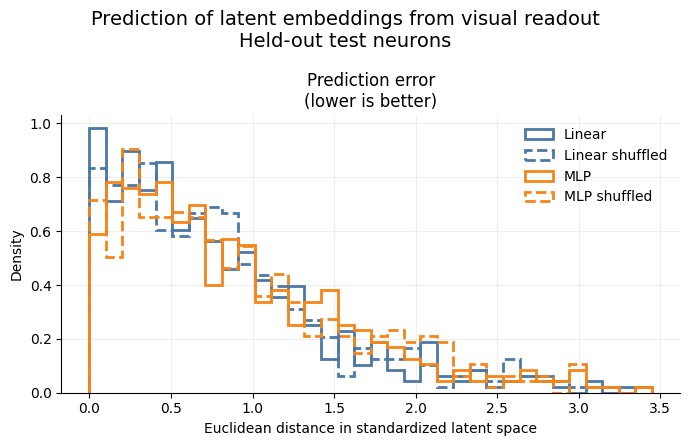

In [37]:
# ============================================================
# How much of the latent vector Z is explained by visual readout?
#
# Models:
#   1. Linear Ridge regression
#   2. Nonlinear MLP
#   3. Ridge trained with shuffled readout/Z pairing
#   4. MLP trained with shuffled readout/Z pairing
#
# Evaluation:
#   - Hyperparameters selected by cross-validation on training neurons
#   - Final metrics calculated only on held-out test neurons
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    explained_variance_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# Parameters
# ============================================================

SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = -1


# ============================================================
# Data
#
# R: visual readout vectors
# Z: complete latent embedding vectors
# ============================================================

latent_cols = sorted(
    [c for c in df_Z_readout.columns if c.startswith("z")],
    key=lambda c: int(c[1:]),
)

R = np.stack(
    df_Z_readout["readout_weight"].to_numpy()
).astype(np.float32)

Z_observed = df_Z_readout[
    latent_cols
].to_numpy(dtype=np.float32)


# Remove neurons containing invalid values
valid_rows = (
    np.isfinite(R).all(axis=1)
    & np.isfinite(Z_observed).all(axis=1)
)

R = R[valid_rows]
Z_observed = Z_observed[valid_rows]

n_neurons_analysis = len(R)
n_latent = Z_observed.shape[1]

print("Number of neurons:", n_neurons_analysis)
print("Readout shape:", R.shape)
print("Latent shape:", Z_observed.shape)


# ============================================================
# Train/test split by neuron
# ============================================================

all_indices = np.arange(n_neurons_analysis)

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=SEED,
)

R_train = R[train_indices]
R_test = R[test_indices]

Z_train = Z_observed[train_indices]
Z_test = Z_observed[test_indices]


# sklearn prefers a 1D target when there is only one output
def target_for_sklearn(Z):
    if Z.shape[1] == 1:
        return Z.ravel()
    return Z


def prediction_to_2d(prediction):
    prediction = np.asarray(prediction)

    if prediction.ndim == 1:
        prediction = prediction[:, None]

    return prediction


Z_train_fit = target_for_sklearn(Z_train)


# ============================================================
# Inner cross-validation
# ============================================================

inner_cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED,
)


# ============================================================
# 1. Linear model: Ridge regression
#
# X and Z are standardized inside each CV fold.
# ============================================================

linear_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "ridge",
            Ridge(),
        ),
    ]),
    transformer=StandardScaler(),
)

linear_search = GridSearchCV(
    estimator=linear_model,
    param_grid={
        "regressor__ridge__alpha": np.logspace(
            -3,
            3,
            7,
        )
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

linear_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_linear = prediction_to_2d(
    linear_search.predict(R_test)
)


# ============================================================
# 2. Nonlinear model: MLP
# ============================================================

mlp_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "mlp",
            MLPRegressor(
                activation="relu",
                solver="adam",
                batch_size=64,
                max_iter=1000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=20,
                random_state=SEED,
            ),
        ),
    ]),
    transformer=StandardScaler(),
)

mlp_search = GridSearchCV(
    estimator=mlp_model,
    param_grid={
        "regressor__mlp__hidden_layer_sizes": [
            (32,),
            (64,),
        ],
        "regressor__mlp__alpha": [
            1e-4,
            1e-3,
        ],
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

mlp_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_mlp = prediction_to_2d(
    mlp_search.predict(R_test)
)


# ============================================================
# Shuffled control
#
# Only the training correspondence between R and Z is shuffled.
# The test set remains unchanged.
#
# The shuffled models use the hyperparameters selected above,
# ensuring the same model complexity.
# ============================================================

rng = np.random.default_rng(SEED)

shuffle_order = rng.permutation(
    len(Z_train)
)

Z_train_shuffled = Z_train[
    shuffle_order
]

Z_train_shuffled_fit = target_for_sklearn(
    Z_train_shuffled
)


linear_shuffled_model = clone(
    linear_search.best_estimator_
)

linear_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_linear_shuffled = prediction_to_2d(
    linear_shuffled_model.predict(R_test)
)


mlp_shuffled_model = clone(
    mlp_search.best_estimator_
)

mlp_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_mlp_shuffled = prediction_to_2d(
    mlp_shuffled_model.predict(R_test)
)


# ============================================================
# Standardize the latent space using training statistics
#
# This prevents one latent dimension from dominating Euclidean
# distance simply because it has a larger numerical scale.
# ============================================================

Z_mean = Z_train.mean(
    axis=0,
    keepdims=True,
)

Z_std = Z_train.std(
    axis=0,
    keepdims=True,
)

Z_std = np.where(
    Z_std < 1e-8,
    1.0,
    Z_std,
)


def standardize_Z(Z):
    return (Z - Z_mean) / Z_std


Z_test_scaled = standardize_Z(
    Z_test
)

predictions_scaled = {
    "Linear": standardize_Z(
        Z_pred_linear
    ),
    "Linear shuffled": standardize_Z(
        Z_pred_linear_shuffled
    ),
    "MLP": standardize_Z(
        Z_pred_mlp
    ),
    "MLP shuffled": standardize_Z(
        Z_pred_mlp_shuffled
    ),
}


# ============================================================
# Vector metrics for each test neuron
# ============================================================

def cosine_by_neuron(Z_true, Z_pred):

    numerator = np.sum(
        Z_true * Z_pred,
        axis=1,
    )

    denominator = (
        np.linalg.norm(Z_true, axis=1)
        * np.linalg.norm(Z_pred, axis=1)
    )

    cosine = np.divide(
        numerator,
        denominator,
        out=np.full_like(
            numerator,
            np.nan,
            dtype=float,
        ),
        where=denominator > 1e-12,
    )

    return cosine


def euclidean_by_neuron(Z_true, Z_pred):

    return np.linalg.norm(
        Z_true - Z_pred,
        axis=1,
    )


vector_distributions = {}
metric_rows = []

for model_name, Z_prediction in predictions_scaled.items():

    euclidean_values = euclidean_by_neuron(
        Z_test_scaled,
        Z_prediction,
    )

    if n_latent >= 2:
        cosine_values = cosine_by_neuron(
            Z_test_scaled,
            Z_prediction,
        )
    else:
        # In one dimension, cosine is essentially only a sign test
        cosine_values = np.full(
            len(Z_test_scaled),
            np.nan,
        )

    vector_distributions[model_name] = {
        "cosine": cosine_values,
        "euclidean": euclidean_values,
    }

    row = {
        "model": model_name,

        "test_R2": r2_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "explained_variance": explained_variance_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "mean_euclidean": np.mean(
            euclidean_values
        ),

        "median_euclidean": np.median(
            euclidean_values
        ),
    }

    if n_latent >= 2:

        row["mean_cosine"] = np.nanmean(
            cosine_values
        )

        row["median_cosine"] = np.nanmedian(
            cosine_values
        )

    else:

        row["pearson_r"] = np.corrcoef(
            Z_test_scaled[:, 0],
            Z_prediction[:, 0],
        )[0, 1]

    metric_rows.append(row)


metrics_df = (
    pd.DataFrame(metric_rows)
    .set_index("model")
)


# ============================================================
# R2 for each individual latent dimension
# ============================================================

per_dimension_results = pd.DataFrame({
    model_name: r2_score(
        Z_test_scaled,
        Z_prediction,
        multioutput="raw_values",
    )
    for model_name, Z_prediction
    in predictions_scaled.items()
})

per_dimension_results.insert(
    0,
    "latent_dimension",
    latent_cols,
)


# ============================================================
# Results
# ============================================================

print("\nBest linear parameters:")
print(linear_search.best_params_)

print("\nBest MLP parameters:")
print(mlp_search.best_params_)

print("\nWhole-vector test metrics:")
display(metrics_df.round(4))

print("\nTest R2 for each latent dimension:")
display(per_dimension_results.round(4))

if n_latent == 1:
    print(
        "\nNote: cosine similarity is not informative for a "
        "one-dimensional latent space. Pearson correlation is "
        "reported instead."
    )


# ============================================================
# Plot distributions on held-out test neurons
# ============================================================

styles = {
    "Linear": {
        "color": "#4C78A8",
        "linestyle": "-",
    },
    "Linear shuffled": {
        "color": "#4C78A8",
        "linestyle": "--",
    },
    "MLP": {
        "color": "#F58518",
        "linestyle": "-",
    },
    "MLP shuffled": {
        "color": "#F58518",
        "linestyle": "--",
    },
}


if n_latent >= 2:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4.5),
    )

    cosine_bins = np.linspace(
        -1,
        1,
        35,
    )

    for model_name, values in vector_distributions.items():

        axes[0].hist(
            values["cosine"],
            bins=cosine_bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=styles[model_name]["color"],
            linestyle=styles[model_name]["linestyle"],
            label=model_name,
        )

    axes[0].set_xlabel(
        "Cosine similarity"
    )

    axes[0].set_ylabel(
        "Density"
    )

    axes[0].set_title(
        "Direction of the predicted latent vector\n(higher is better)"
    )


else:

    fig, ax = plt.subplots(
        1,
        1,
        figsize=(7, 4.5),
    )

    axes = [ax]


all_euclidean_values = np.concatenate([
    values["euclidean"]
    for values in vector_distributions.values()
])

euclidean_max = np.quantile(
    all_euclidean_values,
    0.99,
)

euclidean_bins = np.linspace(
    0,
    max(euclidean_max, 1e-8),
    35,
)

euclidean_axis = (
    axes[1]
    if n_latent >= 2
    else axes[0]
)

for model_name, values in vector_distributions.items():

    euclidean_axis.hist(
        values["euclidean"],
        bins=euclidean_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=styles[model_name]["color"],
        linestyle=styles[model_name]["linestyle"],
        label=model_name,
    )

euclidean_axis.set_xlabel(
    "Euclidean distance in standardized latent space"
)

euclidean_axis.set_ylabel(
    "Density"
)

euclidean_axis.set_title(
    "Prediction error\n(lower is better)"
)

euclidean_axis.legend(
    frameon=False
)


for ax in axes:

    ax.grid(
        alpha=0.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig.suptitle(
    "Prediction of latent embeddings from visual readout\n"
    "Held-out test neurons",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## 36. Inspect the HDF5 layout

Optional recursive file-structure inspection. It can print a large amount of metadata and is not required for training.


In [38]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

/brain_areas <class 'h5py._hl.group.Group'> 
/brain_areas/AL <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7 <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices/AL <class 'h5py._hl.dataset.Dataset'> (387,)
/brain_areas/AL/4_7/meta/area_indices/LM <class 'h5py._hl.dataset.Dataset'> (983,)
/brain_areas/AL/4_7/meta/area_indices/RL <class 'h5py._hl.dataset.Dataset'> (811,)
/brain_areas/AL/4_7/meta/area_indices/V1 <class 'h5py._hl.dataset.Dataset'> (5312,)
/brain_areas/AL/4_7/meta/brain_areas <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/meta/condition_hashes <class 'h5py._hl.dataset.Dataset'> (464,)
/brain_areas/AL/4_7/meta/coordinates <class 'h5py._hl.dataset.Dataset'> (7493, 3)
/brain_areas/AL/4_7/meta/unit_ids <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/trials <class 'h5py._hl.group.Group'> 
/brain_areas/

## 37. Readout distance versus embedding distance

Sample up to 200,000 ordered pairs with replacement, excluding self-pairs. Correlate readout and latent Euclidean distances. Pairs share neurons and can repeat, so the nominal Spearman p-value assumes independence that is not satisfied. Raw latent distances depend on the fitted coordinate scaling.


Z_valid shape: (2375, 1)
F shape: (2375, 512)
Spearman rho = -0.005, p = 4.05e-02


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1679691331.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = res.groupby("bin").agg(


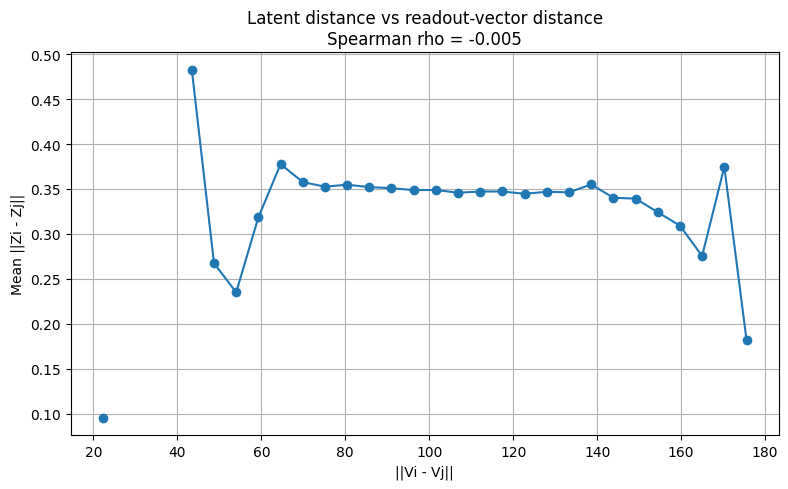

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

feature = "readout_weight"

# neurones valides
df = df_Z_full.dropna(subset=[feature]).copy()

idx = df["neuron_idx"].values

Z_valid = Z[idx]

# IMPORTANT : convertir la colonne de vecteurs en matrice
F = np.stack(
    df[feature].values
).astype(np.float32)

print("Z_valid shape:", Z_valid.shape)
print("F shape:", F.shape)

# -------------------------
# échantillonnage
# -------------------------

n_pairs = 200000
rng = np.random.default_rng(42)

i = rng.integers(0, len(df), n_pairs)
j = rng.integers(0, len(df), n_pairs)

mask = i != j
i = i[mask]
j = j[mask]

# -------------------------
# distances
# -------------------------

latent_dist = np.linalg.norm(
    Z_valid[i] - Z_valid[j],
    axis=1
)

feature_dist = np.linalg.norm(
    F[i] - F[j],
    axis=1
)

rho, pval = spearmanr(
    feature_dist,
    latent_dist
)

print(f"Spearman rho = {rho:.3f}, p = {pval:.2e}")

# -------------------------
# dataframe
# -------------------------

res = pd.DataFrame({
    "feature_dist": feature_dist,
    "latent_dist": latent_dist
})

res["bin"] = pd.cut(
    res["feature_dist"],
    bins=30
)

curve = res.groupby("bin").agg(
    mean_latent=("latent_dist", "mean"),
    n_pairs=("latent_dist", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# -------------------------
# plot
# -------------------------

plt.figure(figsize=(8,5))

plt.plot(
    centers,
    curve["mean_latent"],
    marker="o"
)

plt.xlabel("||Vi - Vj||")
plt.ylabel("Mean ||Zi - Zj||")
plt.title(
    f"Latent distance vs readout-vector distance\nSpearman rho = {rho:.3f}"
)

plt.grid(True)
plt.tight_layout()
plt.show()

## 38. Compare anatomical-distance curves and dimensions

Load dimensions 1, 3 and 7 and compare observed/predicted edge frequencies over all candidate pairs. The MLP output is `p_observed`, not corrected `p_connection`. Different-dimensional latent distances have different scales and should not be compared as an invariant biological metric. This cell overwrites global `model` and `Z`: rerun the selected-model extraction before returning to earlier analyses. A missing optional baseline CSV is now skipped. The dimension-2 plot is skipped unless its embedding was actually loaded.


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 95
Best val loss: 0.0384


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:189: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:218: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.027

Analyzing dim = 3
Loaded best epoch: 98
Best val loss: 0.0374


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:189: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:218: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.053

Analyzing dim = 7
Loaded best epoch: 34
Best val loss: 0.0369


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:189: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_57580\1127597179.py:218: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.047


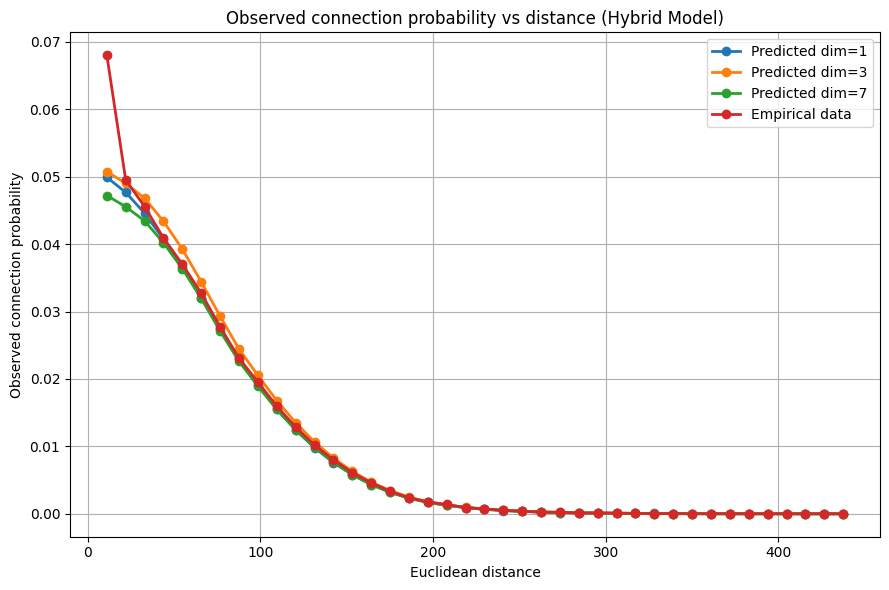

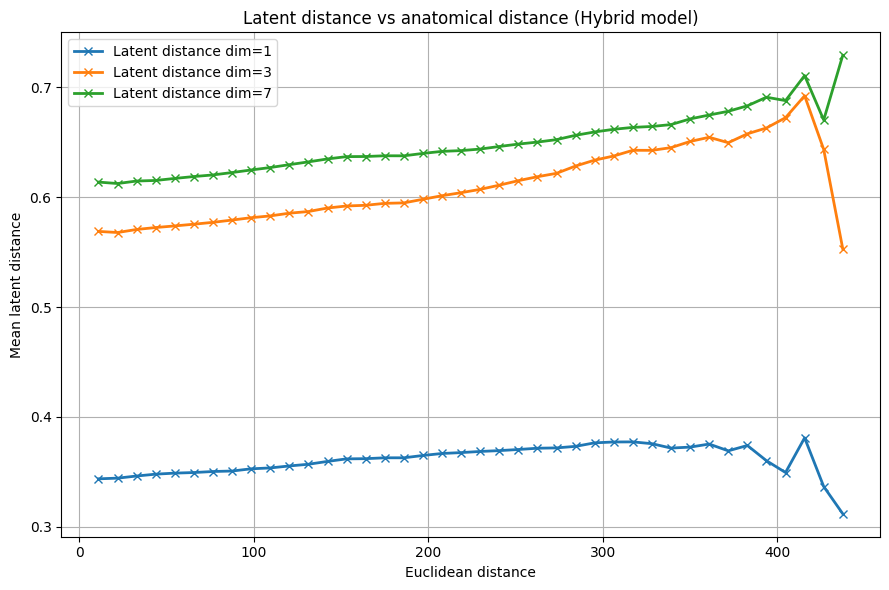

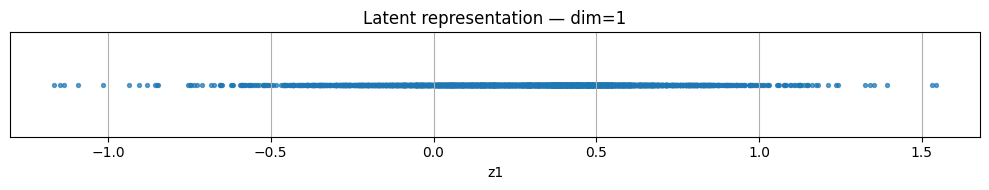

2D display skipped: dimension 2 was not loaded.


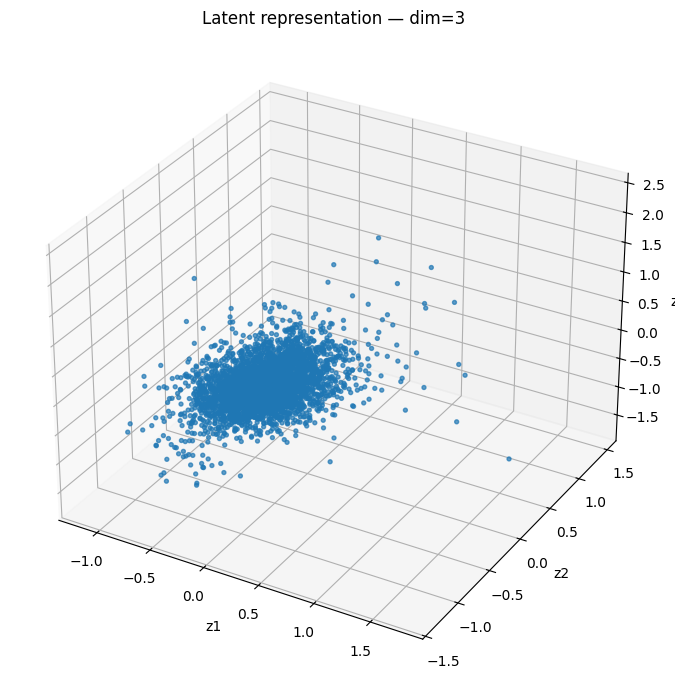

In [40]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 3, 7]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = VisibilityAwareEmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions,
        positions_um=positions_um,
        distance_mean=distance_mean,
        distance_std=distance_std,
        axon_features=axon_features,
        dendrite_features=dendrite_features,
        axon_fully_proofread=axon_fully_proofread,
        dendrite_fully_proofread=dendrite_fully_proofread,
        ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

# Legacy baseline is not plotted below; do not require its file to exist.
if os.path.exists("baselines/geometry_mlp_probability_vs_distance.csv"):
    baseline_curve = pd.read_csv(
            "baselines/geometry_mlp_probability_vs_distance.csv",
            index_col=0
        )

    baseline_centers = np.array([
    pd.Interval(left=float(s.split(",")[0][1:]),
                right=float(s.split(",")[1][:-1])).mid
    for s in baseline_curve.index
    ])

    """plt.plot(
        baseline_curve["bin_center"],
        baseline_curve["predicted_prob"],
        marker="o",
        linestyle="--",
        label="Geometry MLP baseline"
    )"""


plt.xlabel("Euclidean distance")
plt.ylabel("Observed connection probability")
plt.title("Observed connection probability vs distance (Hybrid Model)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )


plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (Hybrid model)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

if 2 in latent_spaces:
    Z2 = latent_spaces[2]

    plt.figure(figsize=(7, 7))

    plt.scatter(
        Z2[:, 0],
        Z2[:, 1],
        s=8,
        alpha=0.7
    )

    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.title("Latent representation — dim=2")

    plt.axis("equal")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("2D display skipped: dimension 2 was not loaded.")


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()